# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [ ]:
# TODO 1.1 — procentul de valori lipsă pe coloană
pct_lipsa = (df.isnull().mean() * 100).sort_values(ascending=False)
print(pct_lipsa)

# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă
df = df.loc[:, df.isnull().mean() <= 0.5]
print("Coloane rămase:", df.columns.tolist())

age         19.865320
embarked     0.224467
pclass       0.000000
survived     0.000000
sex          0.000000
fare         0.000000
dtype: float64
Coloane rămase: ['survived', 'pclass', 'sex', 'age', 'fare', 'embarked']


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [ ]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy()

df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

# TODO 2.2 — verificare + comparație deviație standard
print(df.isnull().sum())
print("Std age înainte:", age_inainte.std())
print("Std age după:   ", df['age'].std())

survived    0
pclass      0
sex         0
age         0
fare        0
embarked    0
dtype: int64
Std age înainte: 14.526497332334044
Std age după:    13.019696550973194


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

Skewness fare: 4.787316519674893
Skewness log_fare: 0.3949280095189306


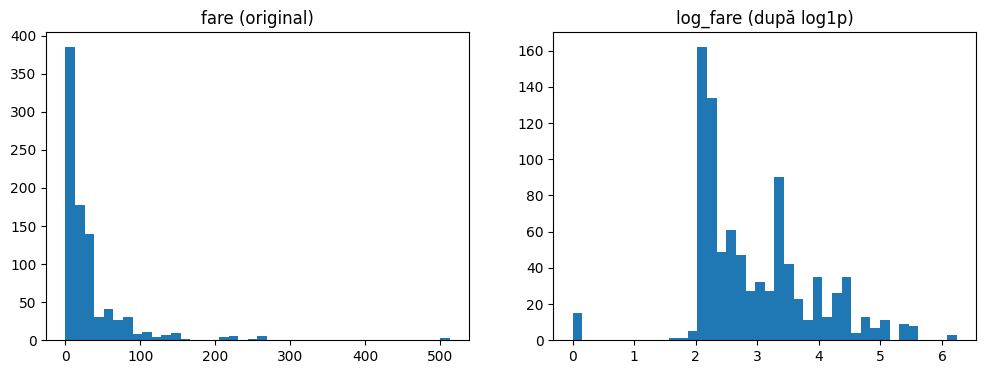

In [ ]:
# TODO 3.1 — skewness fare
print("Skewness fare:", df['fare'].skew())

# TODO 3.2 — coloana log_fare + skewness
df['log_fare'] = np.log1p(df['fare'])
print("Skewness log_fare:", df['log_fare'].skew())

# TODO 3.3 — două histograme
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['fare'], bins=40)
axes[0].set_title('fare (original)')

axes[1].hist(df['log_fare'], bins=40)
axes[1].set_title('log_fare (după log1p)')

plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [ ]:
# TODO 4.1 — limite IQR + număr de outlieri
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1
lim_jos = Q1 - 1.5 * IQR
lim_sus = Q3 + 1.5 * IQR
print(f"Limite: [{lim_jos:.2f}, {lim_sus:.2f}]")

outlieri = ((df['fare'] < lim_jos) | (df['fare'] > lim_sus)).sum()
print("Număr outlieri:", outlieri)

# TODO 4.2 — fare_capped (clip) + maxim înainte/după
df['fare_capped'] = df['fare'].clip(lower=lim_jos, upper=lim_sus)
print("Max înainte:", df['fare'].max())
print("Max după:   ", df['fare_capped'].max())

Limite: [-26.72, 65.63]
Număr outlieri: 116
Max înainte: 512.3292
Max după:    65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [ ]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
df = pd.get_dummies(df, columns=['sex', 'embarked'], drop_first=True, dtype=int)
print(df.head())

# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
scaler = StandardScaler()
df[['age', 'fare_capped']] = scaler.fit_transform(df[['age', 'fare_capped']])

print(df[['age', 'fare_capped']].mean().round(4))
print(df[['age', 'fare_capped']].std().round(4))

   survived  pclass   age     fare  log_fare  fare_capped  sex_male  \
0         0       3  22.0   7.2500  2.110213       7.2500         1   
1         1       1  38.0  71.2833  4.280593      65.6344         0   
2         1       3  26.0   7.9250  2.188856       7.9250         0   
3         1       1  35.0  53.1000  3.990834      53.1000         0   
4         0       3  35.0   8.0500  2.202765       8.0500         1   

   embarked_Q  embarked_S  
0           0           1  
1           0           0  
2           0           1  
3           0           1  
4           0           1  
age            0.0
fare_capped    0.0
dtype: float64
age            1.0006
fare_capped    1.0006
dtype: float64


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

*Răspunsul tău:* Am imputat age deoargece , aceasta are aproximativ 20% valori lipsa, majoritatea datelor fiind reale.
Am eliminat deck pentru ca are majoritatea valorilor lipsa